<a href="https://colab.research.google.com/github/Neethu-Teacher/Assignment-1/blob/main/Assignment_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Loading Dataset**

In [1]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

# Load the dataset
housing = fetch_california_housing()

print("Dataset loaded successfully!")


Dataset loaded successfully!


**Convert dataset into DataFrame**

In [2]:
df = pd.DataFrame( housing.data,
    columns=housing.feature_names)
df['MedHouseVal'] = housing.target
# Display first five rows
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


**Check dataset information**

In [5]:
# Check dataset dimensions
print("Dataset shape:", df.shape)
# Check columns names
print("\nColumn Names:")
print(df.columns)
# Check dataset information
df.info()
# Statistical summary
df.describe()

Dataset shape: (20640, 9)

Column Names:
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


**Check missing values**

In [4]:
# Check missing values
print(df.isnull().sum())

# Total missing values
print("Total Missing Values:", df.isnull().sum().sum())


MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64
Total Missing Values: 0


**Handle missing values**

In [6]:
from sklearn.impute import SimpleImputer
# Create imputer using median strategy
imputer = SimpleImputer(strategy='median')
# Apply imputation
df[df.columns] = imputer.fit_transform(df)
# Check missing values again
print(df.isnull().sum().sum())

0


**Separate independent and dependent variables**

In [7]:
# Independent variables
X = df.drop('MedHouseVal', axis=1)
# Dependent variable
y = df['MedHouseVal']
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (20640, 8)
Target Shape: (20640,)


**Split the dataset intotraining and testing data**

In [8]:
from sklearn.model_selection import train_test_split
# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split( X,y,test_size=0.2,random_state=42)
# Display shapes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (16512, 8)
Testing Features: (4128, 8)
Training Target: (16512,)
Testing Target: (4128,)


**Feature scaling**

In [10]:
from sklearn.preprocessing import StandardScaler
# Create scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)
print("Feature scaling completed successfully!")

Feature scaling completed successfully!


**Linear Regression**

In [11]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression
# Create the model
lr_model = LinearRegression()
# Train the model
lr_model.fit(X_train_scaled, y_train)
# Make predictions
lr_pred = lr_model.predict(X_test_scaled)
print("Linear Regression completed successfully!")


Linear Regression completed successfully!


**Display prdicted values**

In [12]:
# Display first 10 predictions
print("Predicted House Prices:")
print(lr_pred[:10])
print("\nActual House Prices:")
print(y_test[:10].values)

Predicted House Prices:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]

Actual House Prices:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]


**Decision Tree Regressor**

In [13]:
# Import Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor
# Create the model
dt_model = DecisionTreeRegressor( random_state=42,max_depth=10)
# Train the model
dt_model.fit(X_train, y_train)
# Make predictions
dt_pred = dt_model.predict(X_test)
print("Decision Tree Regression completed successfully!")


Decision Tree Regression completed successfully!


**Display predicted values**

In [14]:
# Display first 10 predictions
print("Predicted House Prices:")
print(dt_pred[:10])
print("\nActual House Prices:")
print(y_test[:10].values)

Predicted House Prices:
[0.55230097 0.72655118 4.96858    2.25404688 2.04551471 1.48510526
 2.17611017 1.69809149 2.34255769 4.97827077]

Actual House Prices:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]


**Random Forest Regressor**

In [15]:
# Import Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor
# Create the model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
# Train the model
rf_model.fit(X_train, y_train)
# Make predictions
rf_pred = rf_model.predict(X_test)
print("Random Forest Regression completed successfully!")



Random Forest Regression completed successfully!


**Display predicted values**

In [16]:
print("Predicted House Prices:")
print(rf_pred[:10])
print("\nActual House Prices:")
print(y_test[:10].values)

Predicted House Prices:
[0.5095    0.74161   4.9232571 2.52961   2.27369   1.64692   2.37605
 1.66932   2.7729706 4.9134589]

Actual House Prices:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]


**Gradient Boosting Regressor**

In [17]:
# Import Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
# Create the model
gb_model = GradientBoostingRegressor( n_estimators=100,learning_rate=0.1,  max_depth=3,random_state=42)
# Train the model
gb_model.fit(X_train, y_train)
# Make predictions
gb_pred = gb_model.predict(X_test)
print("Gradient Boosting Regression completed successfully!")

Gradient Boosting Regression completed successfully!


**Display predicted values**

In [18]:
print("Predicted House Prices:")
print(gb_pred[:10])
print("\nActual House Prices:")
print(y_test[:10].values)

Predicted House Prices:
[0.50518761 1.09334601 4.24570956 2.54517359 2.27910301 1.72390996
 2.33719663 1.71977379 3.09962388 4.30446906]

Actual House Prices:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]


**Support Vector Regressor**

In [19]:
# Import Support Vector Regressor
from sklearn.svm import SVR
# Create the model
svr_model = SVR(kernel='rbf', C=100,epsilon=0.1)
# Train the model
svr_model.fit(X_train_scaled, y_train)
# Make predictions
svr_pred = svr_model.predict(X_test_scaled)
print("Support Vector Regression completed successfully!")

Support Vector Regression completed successfully!


**Display Predicted values**

In [20]:
print("Predicted House Prices:")
print(svr_pred[:10])
print("\nActual House Prices:")
print(y_test[:10].values)


Predicted House Prices:
[0.4785635  1.37345633 4.81127341 2.45264696 2.95724933 1.55927099
 2.52787264 1.64464261 2.4391984  4.72860305]

Actual House Prices:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]


**Import Evaluation metrics**

In [21]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
print("Evaluation metrics imported successfully!")


Evaluation metrics imported successfully!


**Calculate MSE, MAE and R²**

In [23]:
# Store actual and predicted values
results = {
    'Linear Regression': (y_test, lr_pred),
    'Decision Tree': (y_test, dt_pred),
    'Random Forest': (y_test, rf_pred),
    'Gradient Boosting': (y_test, gb_pred),
    'SVR': (y_test, svr_pred)
}
# Create an empty list
evaluation_results = []
# Calculate evaluation metrics
for name, (actual, predicted) in results.items():
    mse = mean_squared_error(actual, predicted)
    mae = mean_absolute_error(actual, predicted)
    r2 = r2_score(actual, predicted)
    evaluation_results.append({
        'Model': name,
        'MSE': mse,
        'MAE': mae,
        'R2 Score': r2
    })
# Convert into DataFrame
evaluation_df = pd.DataFrame(evaluation_results)
# Display results
print(evaluation_df)

               Model       MSE       MAE  R2 Score
0  Linear Regression  0.555892  0.533200  0.575788
1      Decision Tree  0.415468  0.433203  0.682948
2      Random Forest  0.255368  0.327543  0.805123
3  Gradient Boosting  0.293997  0.371643  0.775645
4                SVR  0.320104  0.371703  0.755722


**Identify best and worst models**

In [24]:
# Identify best model
best_model = evaluation_df.loc[ evaluation_df['R2 Score'].idxmax()]
# Identify worst model
worst_model = evaluation_df.loc[evaluation_df['R2 Score'].idxmin()]
print("Best Performing Model:")
print(best_model)
print("\nWorst Performing Model:")
print(worst_model)


Best Performing Model:
Model       Random Forest
MSE              0.255368
MAE              0.327543
R2 Score         0.805123
Name: 2, dtype: object

Worst Performing Model:
Model       Linear Regression
MSE                  0.555892
MAE                    0.5332
R2 Score             0.575788
Name: 0, dtype: object


**Visualize model perfomance**
**MSE Comparison**

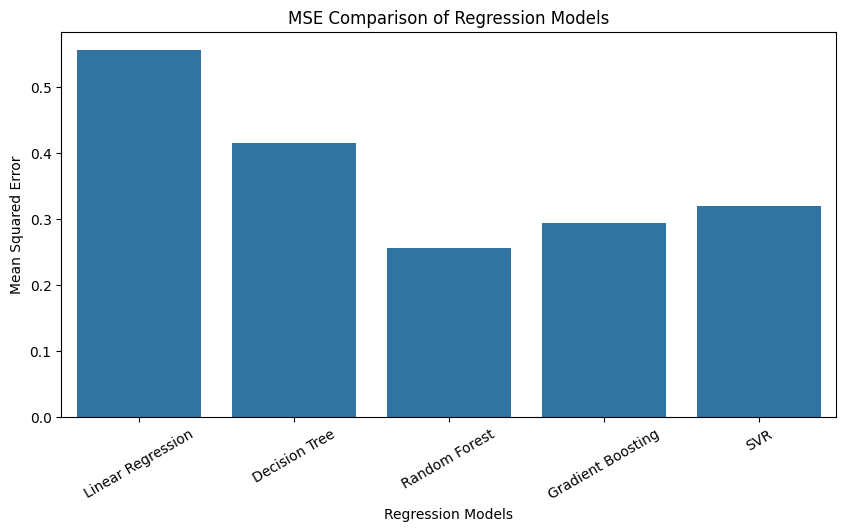

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.barplot(data=evaluation_df, x='Model', y='MSE')
plt.title('MSE Comparison of Regression Models')
plt.xlabel('Regression Models')
plt.ylabel('Mean Squared Error')
plt.xticks(rotation=30)
plt.show()

**R² score comparison**

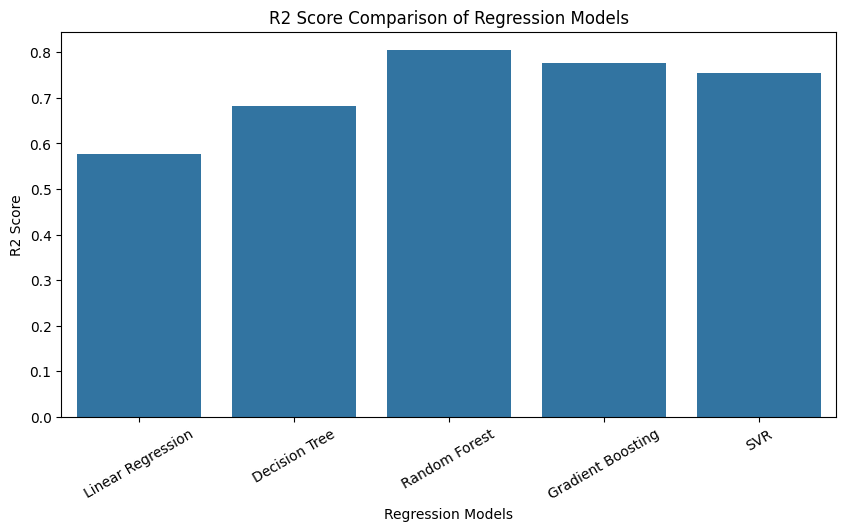

In [27]:
plt.figure(figsize=(10, 5))
sns.barplot(data=evaluation_df,x='Model',y='R2 Score')
plt.title('R2 Score Comparison of Regression Models')
plt.xlabel('Regression Models')
plt.ylabel('R2 Score')
plt.xticks(rotation=30)
plt.show()


# Assignment interpretation

** Explanation of preprocessing steps**

Loaded the California Housing dataset using fetch_california_housing().

Converted the dataset into a Pandas DataFrame.

Checked missing values and handled them using median imputation.

Separated independent variables (X) and dependent variable (y).

Split the dataset into 80% training data and 20% testing data.

Applied StandardScaler to standardize features for Linear Regression and SVR.


# Conclusion

The California Housing dataset was used to implement five supervised regression algorithms: Linear Regression, Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor and Support Vector Regressor.
The models were evaluated using Mean Squared Error (MSE), Mean Absolute Error (MAE) and R-squared (R²) score.
Based on the evaluation results, the best-performing and worst-performing regression algorithms were identified. This comparison helps us understand the effectiveness of different regression techniques in predicting house prices.
**Model Evaluation and Comparison**
Five regression algorithms were evaluated using Mean Squared Error (MSE), Mean Absolute Error (MAE), and R-squared (R²) score.
**Best Performing Model: Random Forest Regressor**
Random Forest achieved the best performance with an MSE of 0.255368, MAE of 0.327543, and R² score of 0.805123. It performed better than the other algorithms because it combines multiple decision trees and can capture complex nonlinear relationships in the dataset.
**Worst Performing Model: Linear Regression**
Linear Regression showed the lowest performance with an MSE of 0.555892, MAE of 0.533200, and R² score of 0.575788. This may be because the relationship between house prices and the input features is not entirely linear.
**Overall Comparison**
Random Forest performed best, followed by Gradient Boosting, SVR, Decision Tree, and Linear Regression. Therefore, Random Forest is the most suitable model among the five algorithms for predicting California house prices based on these evaluation results.